# 历史股票池、回溯性时间外验证与可执行回测

本报告读取 `src/advanced_research.py` 生成的结果。股票池在每个五日调仓截面按历史成员重建；2020–2023 为开发期，2024–2025 为回溯性时间外验证区间。原项目和 Git 历史已经包含该区间的收益，因此这里不把它称为事先冻结的锁定样本外。

In [1]:
from pathlib import Path
import json
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/advanced_research.py').exists())
RESULTS = ROOT / 'data/processed/advanced'
FIGURES = ROOT / 'figures'

In [2]:
quality = json.loads((RESULTS / 'data_quality.json').read_text(encoding='utf-8'))
summary = pd.read_csv(RESULTS / 'rank_ic_by_stage.csv')
performance = pd.read_csv(RESULTS / 'executable_performance.csv')
print(json.dumps(quality, ensure_ascii=False, indent=2))
display(summary.round(4))
display(performance.round(4))

{
  "membership_snapshots": 291,
  "membership_rows": 87300,
  "all_membership_snapshots_have_300_codes": true,
  "historical_union_codes": 481,
  "current_constituent_codes": 300,
  "historical_codes_no_longer_current": 193,
  "current_codes_outside_research_window": 12,
  "price_rows": 731507,
  "price_codes": 481,
  "price_date_start": "2019-07-01",
  "price_date_end": "2025-12-31",
  "duplicate_price_keys": 0,
  "null_ohlc_fields": {
    "open": 0,
    "high": 0,
    "low": 0,
    "close": 0,
    "preclose": 0
  },
  "membership_rows_without_same_day_price": 1,
  "signal_dates": 291,
  "signal_rows": 85444,
  "duplicate_signal_keys": 0,
  "signal_rows_per_date": {
    "minimum": 282,
    "median": 294.0,
    "maximum": 300
  },
  "minimum_active_history_days": 120.0,
  "minimum_adv20_cny": 30305933.285000004,
  "execution_lag_calendar_days": {
    "1": 71343,
    "3": 11759,
    "4": 578,
    "5": 598,
    "6": 299,
    "8": 584,
    "11": 283
  },
  "rows_without_realized_exit_lab

## 核心图

- 20 日动量在开发期与回溯性时间外验证中均为负 RankIC，且未达到显著。
- 时间外 Q5 总收益略高于动态等权基准，但 Sharpe 更低、最大回撤更大，未形成稳定风险调整优势。
- 做空腿仅保留为研究诊断；A 股个股融券可得性不支持把它当成默认可执行策略。

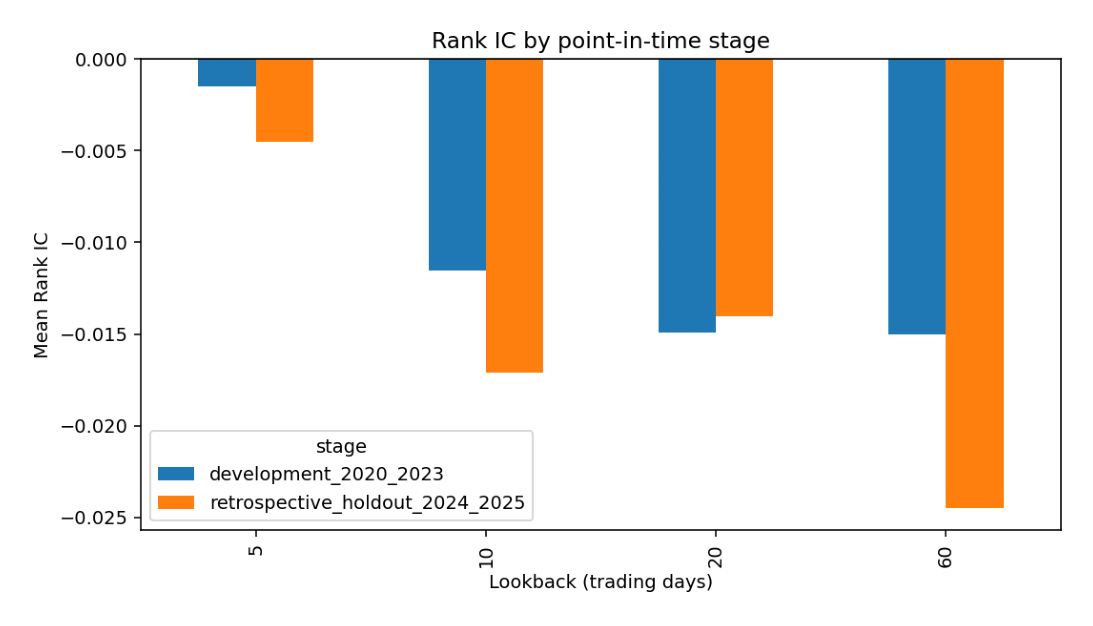

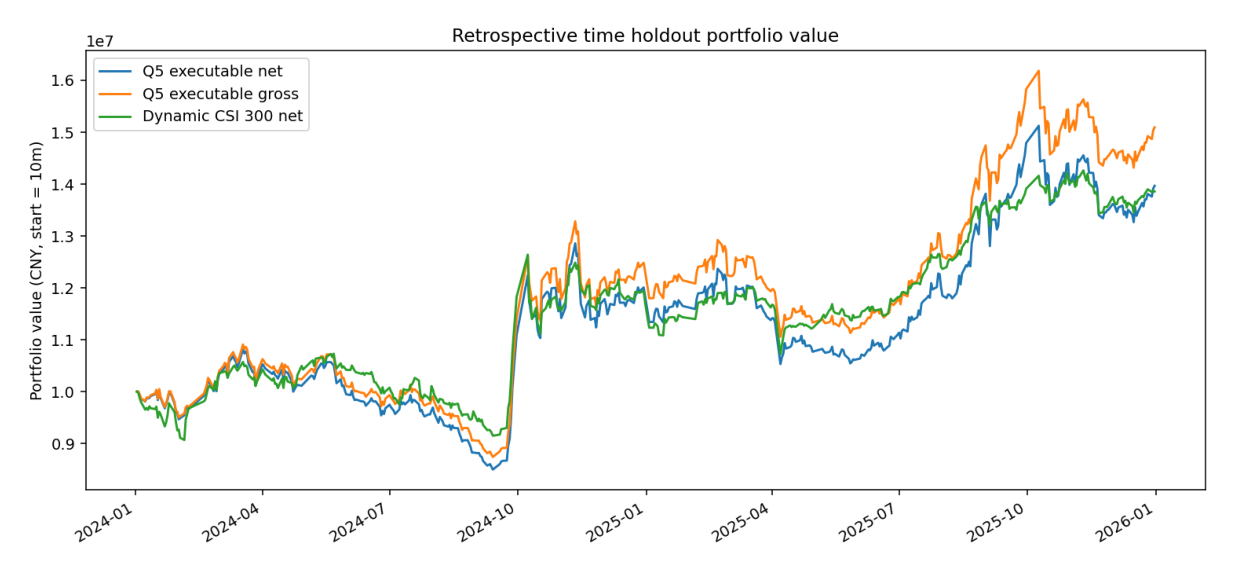

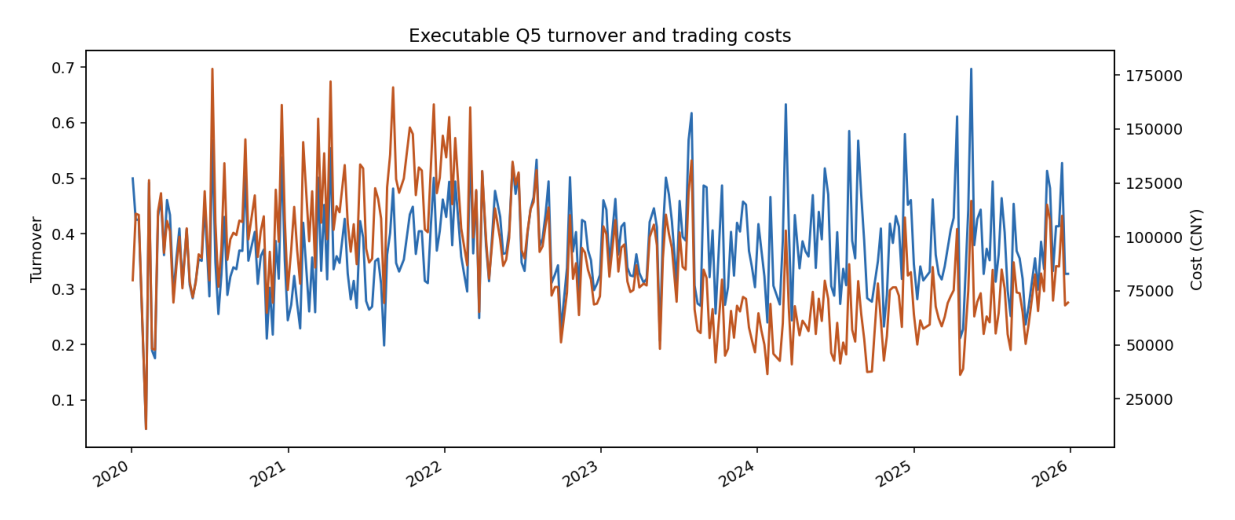

In [3]:
for filename in [
    '04_stage_rank_ic.png',
    '04_retrospective_holdout_nav.png',
    '04_turnover_and_costs.png',
]:
    image = mpimg.imread(FIGURES / filename)
    plt.figure(figsize=(12, 6))
    plt.imshow(image)
    plt.axis('off')
    plt.show()